# 01 – Data Collection and Exploration
## MLOps Model Monitoring & Data Drift Dashboard

**Objective:** Load the Breast Cancer Wisconsin dataset, inspect its structure, understand the target, check data quality, explore feature distributions, and save a clean reference dataset for later steps.

### Dataset source
This notebook uses `sklearn.datasets.load_breast_cancer`, so no manual dataset download is required. Scikit-learn bundles the dataset with the package.

**Target:** `target`  
- `0` = malignant  
- `1` = benign  

We will retain the original feature columns and add the target column to the exported CSV.


## 1. Import required libraries

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Make project root importable when this notebook is run from the notebook/ folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from config.paths_config import (
    DATA_DIR,
    BASELINE_DATA_PATH,
    create_project_directories,
)

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Python version: 3.14.4
Project root: d:\NeoAI
Data directory: D:\NeoAI\artifacts\data


## 2. Load the Breast Cancer Wisconsin dataset

In [2]:
# Load the dataset as a pandas DataFrame
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Dataset loaded successfully.")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully.
Feature matrix shape: (569, 30)
Target shape: (569,)


## 3. Understand dataset rows and columns

In [3]:
# Combine features and target into one DataFrame
df = X.copy()
df["target"] = y

print("First five records:")
display(df.head())

print("\\nDataset shape (rows, columns):", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


\nDataset shape (rows, columns): (569, 31)
\nColumn names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter   

## 4. Dataset description and statistical summary

In [4]:
print("Dataset description:")
print(dataset.DESCR[:2500])

print("\\nNumerical statistical summary:")
display(df.describe().T)

Dataset description:
.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is 

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 5. Identify the target variable

In [5]:
target_column = "target"

print("Target column:", target_column)
print("Target meaning:")
for class_value, class_name in enumerate(dataset.target_names):
    print(f"{class_value} = {class_name}")

print("\\nTarget values:")
print(sorted(df[target_column].unique()))

Target column: target
Target meaning:
0 = malignant
1 = benign
\nTarget values:
[np.int64(0), np.int64(1)]


## 6. Check missing values and duplicate records

In [6]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percentage": (missing_values / len(df)) * 100
})

display(missing_summary[missing_summary["missing_count"] > 0])

if missing_summary["missing_count"].sum() == 0:
    print("No missing values found.")

duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

,missing_count,missing_percentage


No missing values found.
Duplicate rows: 0


## 7. Understand class distribution

,class_value,class_name,record_count,percentage
0,0,malignant,212,37.258348
1,1,benign,357,62.741652


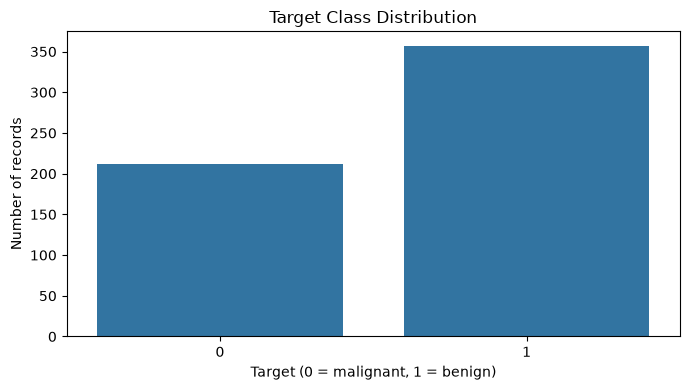

In [7]:
class_counts = df[target_column].value_counts().sort_index()
class_names = {0: "malignant", 1: "benign"}

class_summary = pd.DataFrame({
    "class_value": class_counts.index,
    "class_name": [class_names[i] for i in class_counts.index],
    "record_count": class_counts.values,
    "percentage": (class_counts.values / len(df)) * 100
})

display(class_summary)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target_column)
plt.title("Target Class Distribution")
plt.xlabel("Target (0 = malignant, 1 = benign)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 8. Explore feature distributions

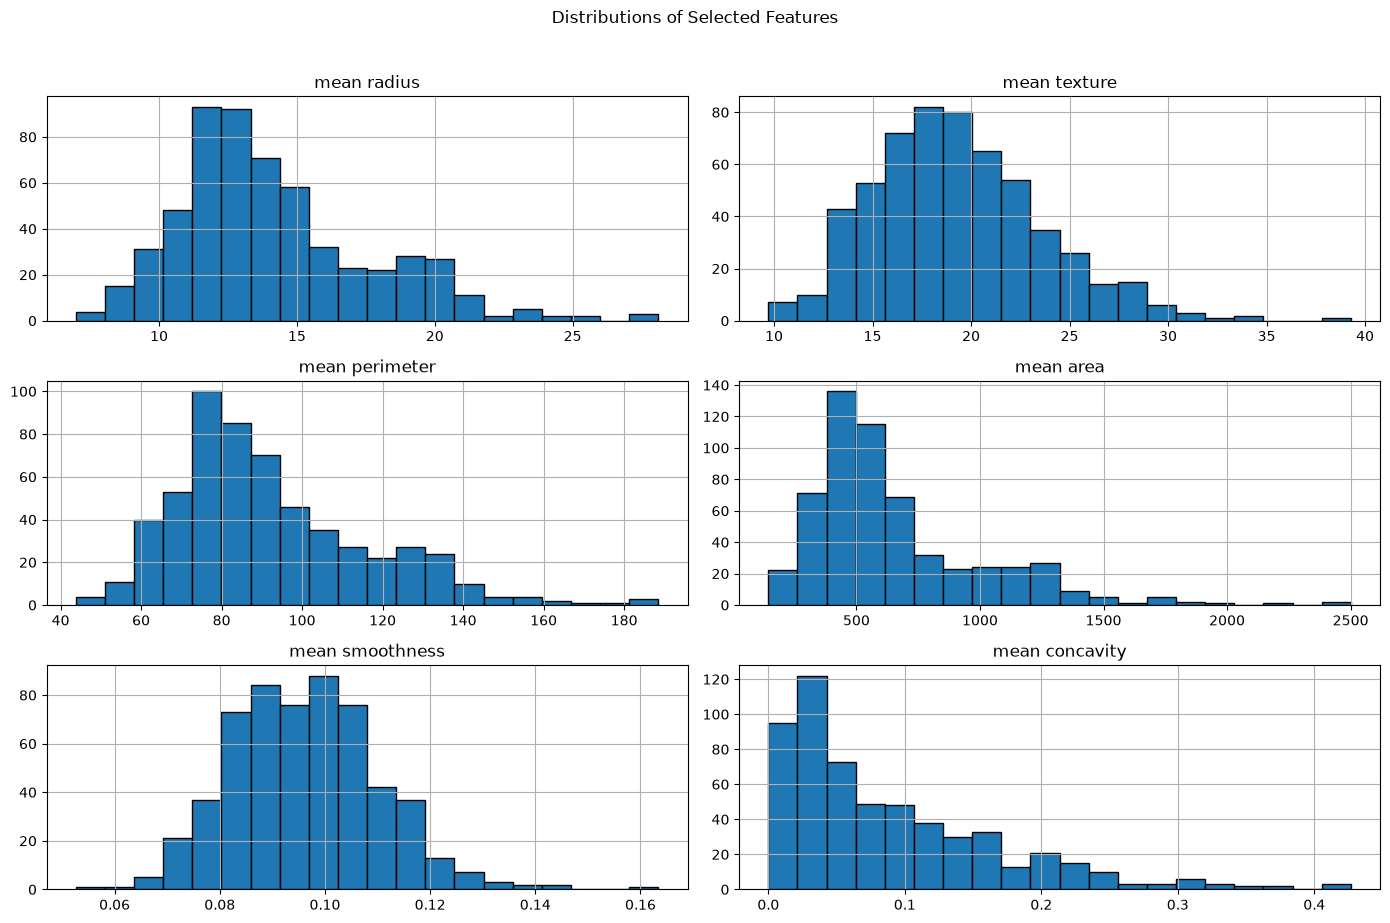

In [8]:
# Plot distributions for a small, representative selection of features
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity",
]

df[selected_features].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distributions of Selected Features", y=1.02)
plt.tight_layout()
plt.show()

## 9. Compare selected features by target class

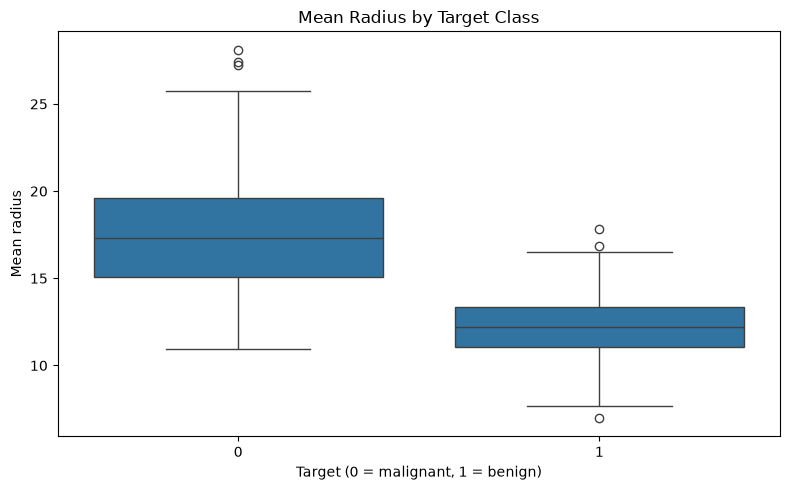

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=target_column, y="mean radius")
plt.title("Mean Radius by Target Class")
plt.xlabel("Target (0 = malignant, 1 = benign)")
plt.ylabel("Mean radius")
plt.tight_layout()
plt.show()

## 10. Explore feature correlations

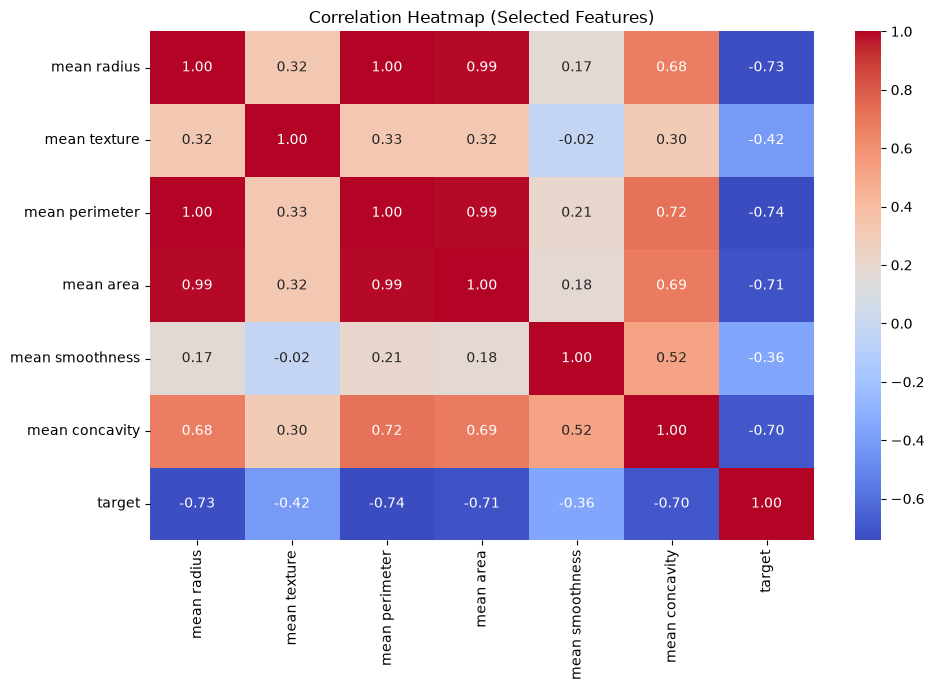

In [10]:
# Correlation matrix for a subset keeps the plot readable
correlation_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity",
    "target",
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[correlation_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap (Selected Features)")
plt.tight_layout()
plt.show()

## 11. Prepare and save the reference dataset

In [11]:
# Create required project folders
create_project_directories()

# Keep the original feature columns and target
reference_df = X.copy()
reference_df[target_column] = y

# Save the reference dataset for subsequent project steps
reference_df.to_csv(BASELINE_DATA_PATH, index=False)

print("Reference dataset saved successfully.")
print("Saved location:", BASELINE_DATA_PATH)
print("Saved shape:", reference_df.shape)

Reference dataset saved successfully.
Saved location: D:\NeoAI\artifacts\data\baseline_data.csv
Saved shape: (569, 31)


## 12. Final validation and observations

Run the checks below before moving to Step 3.

Expected dataset dimensions:
- 569 rows
- 30 input features
- 1 target column
- 31 columns in the exported CSV

The dataset is bundled with Scikit-learn; no separate download is necessary.

### Observations to record
1. The dataset contains numerical features describing cell nuclei.
2. The target is binary: malignant (0) or benign (1).
3. The dataset has 569 records and 30 input features.
4. Check the notebook output for missing values and duplicates rather than assuming they are absent.
5. The saved `baseline_data.csv` will be the reference dataset used by later training and monitoring steps.


In [13]:
# Final checks
assert reference_df.shape == (569, 31), "Unexpected dataset shape"
assert target_column in reference_df.columns, "Target column is missing"
assert set(reference_df[target_column].unique()) == {0, 1}, "Unexpected target classes"
assert BASELINE_DATA_PATH.exists(), "Baseline CSV was not saved"

